## Phase 3: Exploratory Data analysis 
**The goal is : Explore the cleaned dataset and discover patterns, distributions, relationships, and interesting facts.**

In [87]:
import pandas as pd 
df=pd.read_csv("../Data/processed/Ai_jobs_cleaned.csv")
df.info()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 1503 entries, 0 to 1502
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   job title        1503 non-null   str  
 1   company          1503 non-null   str  
 2   region           1503 non-null   str  
 3   skills required  1503 non-null   str  
 4   is remote?       1503 non-null   str  
 5   is fresher?      1503 non-null   str  
 6   job_category     1503 non-null   str  
dtypes: str(7)
memory usage: 177.6 KB


(1503, 7)

In [88]:
df.head()

,job title,company,region,skills required,is remote?,is fresher?,job_category
0,Data analyst,BP Energy,Pune,Unknown,no,no,Data analyst
1,Data analyst,Arcadis,Bengaluru,"Big Data, Database",no,no,Data analyst
2,Data analyst,Scan Holdings Pvt. Limited,Delhi,Unknown,no,unknown,Data analyst
3,Data analyst,BOEING,Bengaluru,Unknown,no,unknown,Data analyst
4,Data analyst,Boston Consulting Group,New Delhi,Unknown,no,unknown,Data analyst


**1- Which type of job is most common :**

In [89]:
df["job_category"].value_counts()

job_category
Data scientist    676
Data analyst      665
ML engineer       162
Name: count, dtype: int64

In [90]:
df["job_category"].value_counts(normalize=True) * 100

job_category
Data scientist    44.976713
Data analyst      44.244844
ML engineer       10.778443
Name: proportion, dtype: float64

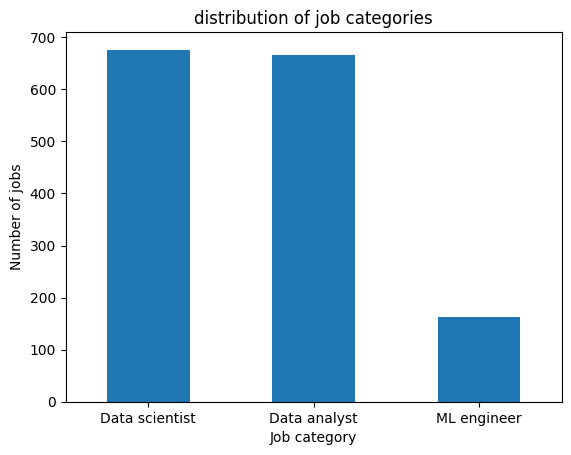

In [91]:
import matplotlib.pyplot as plt
df["job_category"].value_counts().plot(kind="bar")
plt.title("distribution of job categories")
plt.xlabel("Job category")
plt.ylabel("Number of jobs")
plt.xticks(rotation=0)
plt.show()

**Interpretation :** *The distribution shows that Data Scientist positions represent the largest category, with 676 postings (approximately 44.98%), closely followed by Data Analyst positions, with 665 postings (44.24%). In contrast, ML Engineer positions account for only 162 postings (10.78%). This indicates that the dataset contains considerably fewer ML Engineer postings than the other two categories. Therefore, comparisons involving ML Engineer roles should take this difference in representation into account.*

**2-Which type of jobs has more remote opportunities**

In [92]:
df["is remote?"].value_counts()

is remote?
no     1312
yes     191
Name: count, dtype: int64

In [93]:
df.groupby("job_category")["is remote?"].value_counts()

job_category    is remote?
Data analyst    no            589
                yes            76
Data scientist  no            591
                yes            85
ML engineer     no            132
                yes            30
Name: count, dtype: int64

**- In percentage :**

In [94]:
remote_percentage=(
    df.groupby("job_category")["is remote?"].value_counts(normalize=True).mul(100)
)
print(remote_percentage)

job_category    is remote?
Data analyst    no            88.571429
                yes           11.428571
Data scientist  no            87.426036
                yes           12.573964
ML engineer     no            81.481481
                yes           18.518519
Name: proportion, dtype: float64


**3-Fresher opportunities:**

In [95]:
df["is fresher?"].value_counts()

is fresher?
unknown    1051
no          449
yes           3
Name: count, dtype: int64

In [96]:
df.groupby("job_category")["is fresher?"].value_counts()

job_category    is fresher?
Data analyst    unknown        508
                no             157
Data scientist  unknown        441
                no             232
                yes              3
ML engineer     unknown        102
                no              60
Name: count, dtype: int64

**- in percentage :**

In [97]:
fresher_percentage = (
    df.groupby("job_category")["is fresher?"].value_counts(normalize=True).mul(100)
    )
print(fresher_percentage)

job_category    is fresher?
Data analyst    unknown        76.390977
                no             23.609023
Data scientist  unknown        65.236686
                no             34.319527
                yes             0.443787
ML engineer     unknown        62.962963
                no             37.037037
Name: proportion, dtype: float64


**4-Which regions have the most jobs :**

In [98]:
df["region"].value_counts().head(10)

region
Bengaluru    436
Hyderabad    134
Mumbai       116
Pune          95
Gurgaon       92
Remote        67
India         66
Chennai       56
Noida         42
Kolkata       31
Name: count, dtype: int64

**- Visualize it :**

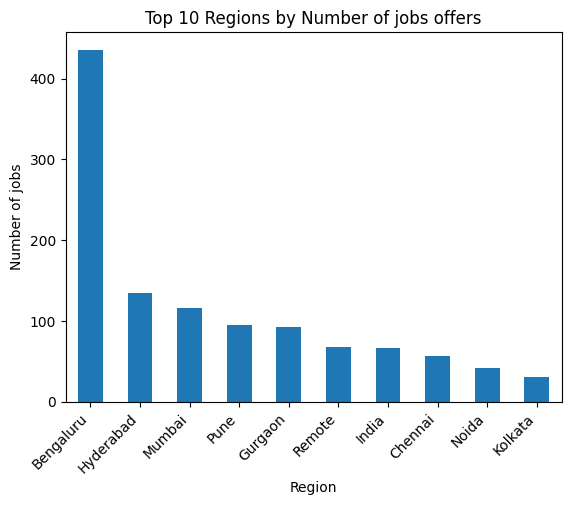

In [99]:
df["region"].value_counts().head(10).plot(kind="bar")

plt.title("Top 10 Regions by Number of jobs offers")
plt.xlabel("Region")
plt.ylabel("Number of jobs")
plt.xticks(rotation=45 , ha="right")
plt.show()

**Interpretation:** *Bengaluru clearly dominates the regional distribution, with +400 job postings, making it the most represented location in the dataset. Hyderabad follows with 134 postings, followed by Mumbai with 116. Pune and Gurgaon also appear among the leading locations, with 95 and 92 postings, respectively. The difference between Bengaluru and the other regions is substantial, suggesting that the dataset is heavily concentrated in this location. However, these results describe the collected dataset and do not necessarily reflect the complete distribution of job opportunities across India.*

**5-Required skills :**

In [100]:
df["skills required"].value_counts().head(20)

skills required
Unknown               907
Stat                   49
Machine Learning       48
Data Mining            36
Python                 35
Database               34
Excel                  24
Data Visualization     22
Ai                     22
Big Data               21
Data Structure         20
Etl                    16
Sql                    14
Deployment             14
Deep Learning          12
Dashboard              10
Python, Stat            8
Cloud                   8
Preprocessing           8
Data Mining, Stat       7
Name: count, dtype: int64

**-We should extract individual skills , so let's create a separate analysis without modifying our original column yet**

In [101]:
from collections import Counter

skills_series = (
    df["skills required"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

skills_series = skills_series[
    skills_series.ne("")
    & skills_series.str.casefold().ne("unknown")
]

skill_counts = Counter(skills_series)

print(skill_counts.most_common(20))

[('Stat', 100), ('Python', 89), ('Machine Learning', 76), ('Data Mining', 60), ('Data Visualization', 58), ('Database', 53), ('Big Data', 44), ('Excel', 42), ('Ai', 41), ('Deep Learning', 35), ('Sql', 33), ('Data Structure', 31), ('Etl', 25), ('Deployment', 21), ('Dashboard', 18), ('Preprocessing', 15), ('Pytorch', 15), ('Tableau', 14), ('R', 13), ('Cloud', 11)]


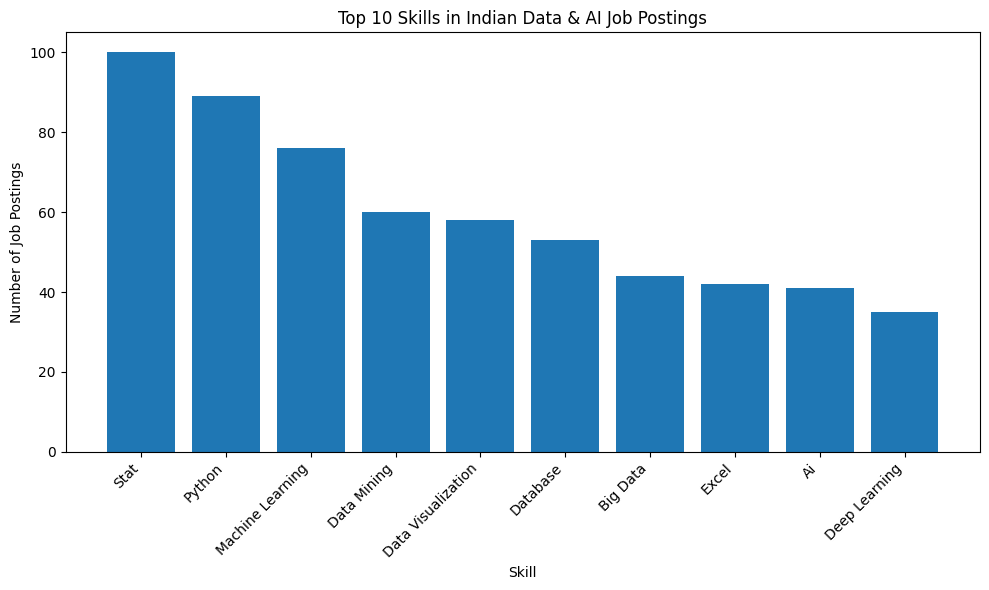

In [102]:
import matplotlib.pyplot as plt

top_skills = skill_counts.most_common(10)

skill_names = [skill for skill, count in top_skills]
skill_values = [count for skill, count in top_skills]

plt.figure(figsize=(10, 6))
plt.bar(skill_names, skill_values)

plt.title("Top 10 Skills in Indian Data & AI Job Postings")
plt.xlabel("Skill")
plt.ylabel("Number of Job Postings")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


**Interpretation:** *After excluding postings with unknown skill information and separating individual skills, the analysis identifies the most frequently mentioned technical skills in the dataset. These results help highlight the skills that appear most often in the collected Data and AI job postings. However, because many records do not contain skill information, the ranking represents recorded skill mentions rather than the complete requirements of the Indian job market. The results should therefore be interpreted with this limitation in mind.*

**6-Skills requirements by job category**

In [103]:
skills_by_category = (
    df[["job_category", "skills required"]]
    .dropna(subset=["skills required"])
    .assign(
        skill=lambda data: data["skills required"].str.split(",")
    )
    .explode("skill")
)

skills_by_category["skill"] = (
    skills_by_category["skill"].str.strip()
)

skills_by_category = skills_by_category[
    skills_by_category["skill"].str.casefold() != "unknown"
]

top_skills_by_category = (
    skills_by_category
    .groupby("job_category")["skill"]
    .value_counts()
    .groupby(level=0, group_keys=False)
    .head(10)
)

print(top_skills_by_category)


job_category    skill             
Data analyst    Database              53
                Data Visualization    39
                Excel                 38
                Stat                  36
                Python                25
                Data Mining           20
                Sql                   19
                Machine Learning      14
                Dashboard             14
                Tableau               14
Data scientist  Machine Learning      62
                Python                56
                Stat                  51
                Data Mining           40
                Big Data              29
                Data Structure        19
                Data Visualization    19
                Etl                   15
                Preprocessing         14
                Sql                   13
ML engineer     Ai                    41
                Deep Learning         26
                Deployment            17
                Pytorc

**- Visualize the results :**

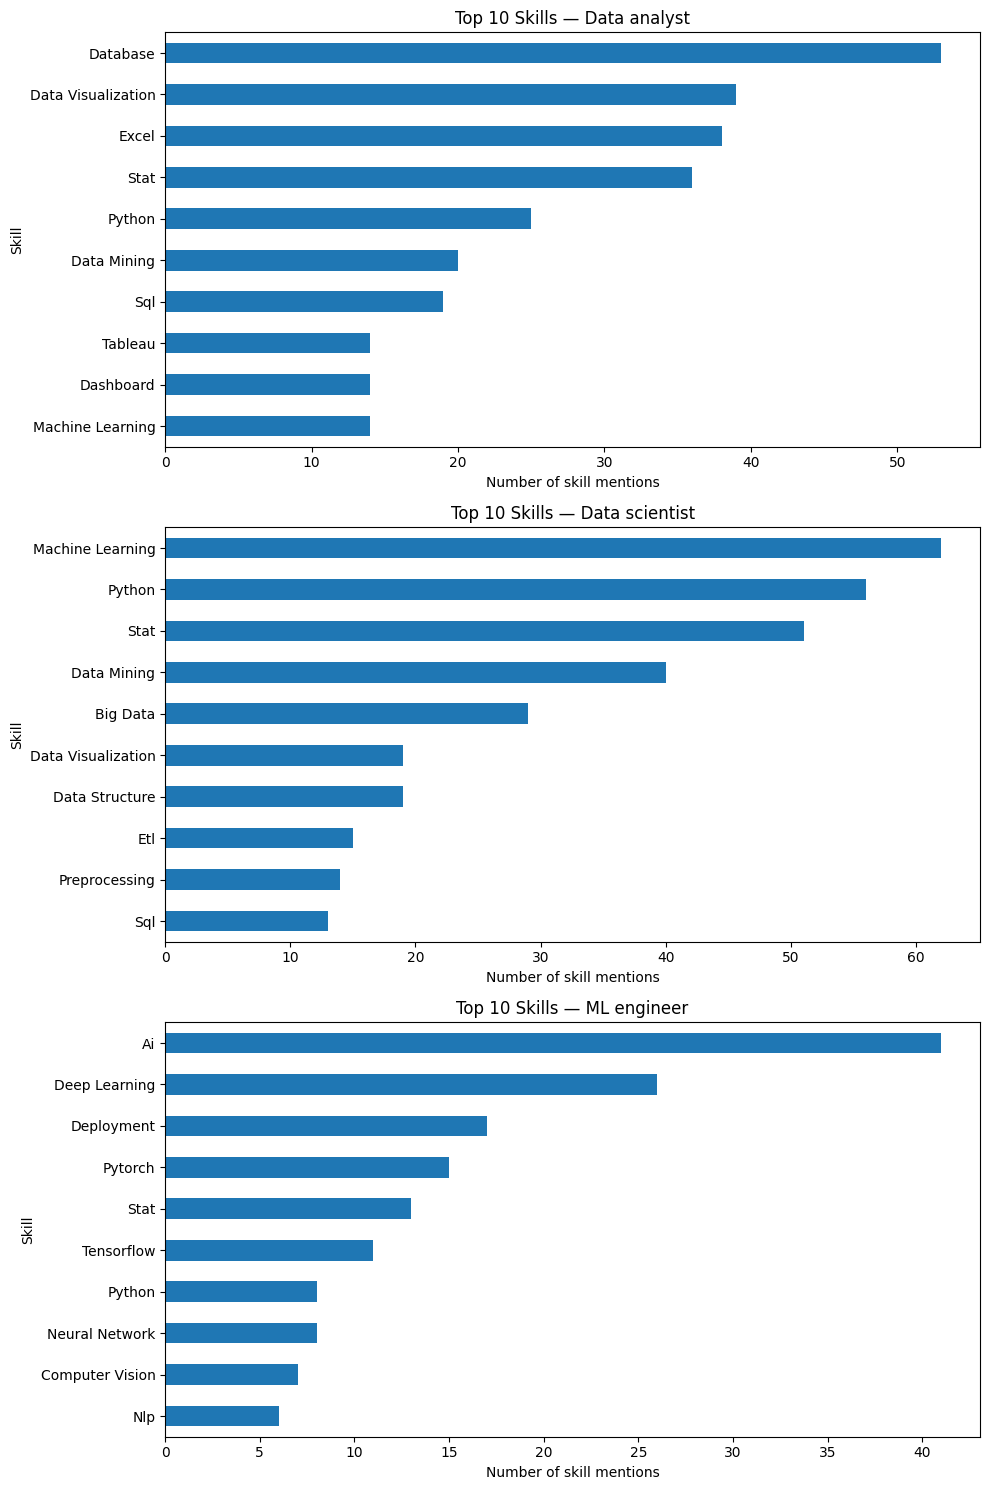

In [104]:
categories = skills_by_category["job_category"].dropna().unique()

fig, axes = plt.subplots(
    nrows=len(categories),
    ncols=1,
    figsize=(10, 5 * len(categories))
)

if len(categories) == 1:
    axes = [axes]

for ax, category in zip(axes, categories):
    counts = (
        skills_by_category.loc[
            skills_by_category["job_category"] == category,
            "skill"
        ]
        .value_counts()
        .head(10)
        .sort_values()
    )

    counts.plot(kind="barh", ax=ax)
    ax.set_title(f"Top 10 Skills — {category}")
    ax.set_xlabel("Number of skill mentions")
    ax.set_ylabel("Skill")

plt.tight_layout()
plt.show()

**Interpretation:** 

*1-Database is the most frequently mentioned skill among the recorded requirements for Data Analyst positions, with 53 mentions. Data Visualization follows with 39 mentions, while Excel and Statistics (Stat) have 38 and 36 mentions, respectively. Python appears 25 times, highlighting its presence in this category as well. These results suggest that the recorded Data Analyst requirements cover data management, statistical analysis, visualization, and programming. However, the high number of postings with unknown skill information means these counts may not fully represent employers' requirements.*

*2-Machine Learning is the most frequently mentioned skill for Data Scientist positions, with 62 mentions, followed by Python with 56 and Statistics (Stat) with 51. Data Mining also appears frequently, with 40 mentions, while Big Data has 29 mentions. This distribution highlights the importance of programming, statistical methods, and machine learning in the recorded Data Scientist requirements. Compared with Data Analyst positions, Machine Learning and Python are more prominent in this category.*

*3-AI is the most frequently mentioned skill for ML Engineer positions, with 41 mentions, followed by Deep Learning with 26 and Deployment with 17. PyTorch appears 15 times, while TensorFlow is mentioned 11 times. Neural Networks, Computer Vision, and NLP also appear among the leading recorded skills. These results suggest a stronger emphasis on AI model development, deep learning frameworks, and deployment-related skills in this category. Nevertheless, ML Engineer postings are less represented in the dataset, and many postings have unknown skill information.*

**7-Investigate missing values and data quality**

**7-1.Check missing values:**

In [105]:
missing_summary = pd.DataFrame({
    "Missing count": df.isna().sum(),
    "Missing percentage": (df.isna().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    "Missing percentage",
    ascending=False
)

print(missing_summary)

                 Missing count  Missing percentage
job title                    0                 0.0
company                      0                 0.0
region                       0                 0.0
skills required              0                 0.0
is remote?                   0                 0.0
is fresher?                  0                 0.0
job_category                 0                 0.0


**Interpretation:** *The missing-value report shows zero actual null values across all columns because missing information was replaced with the string "Unknown" during the cleaning phase. However, 907 postings (60.35%) have unknown skill information, and 1,051 postings (69.93%) have unknown fresher status. These values reveal that important information is still unavailable despite the absence of technical null values. This limitation should be considered when interpreting the skill and fresher analyses.*

In [106]:
# Count "Unknown" values in relevant columns
for column in ["skills required", "is fresher?"]:
    unknown_count = (
        df[column]
        .astype("string")
        .str.strip()
        .str.casefold()
        .eq("unknown")
        .sum()
    )

    percentage = unknown_count / len(df) * 100

    print(f"{column}: {unknown_count} unknown values "
          f"({percentage:.2f}%)")

skills required: 907 unknown values (60.35%)
is fresher?: 1051 unknown values (69.93%)


**7-2.Investigate and handle duplicate rows**

In [107]:
duplicate_rows = df[df.duplicated(keep=False)].sort_values(
    by=["job title", "company", "region"]
)

duplicate_rows.head(20)

,job title,company,region,skills required,is remote?,is fresher?,job_category
181,Data analyst,ABB,Bengaluru,Unknown,no,unknown,Data analyst
227,Data analyst,ABB,Bengaluru,Unknown,no,unknown,Data analyst
200,Data analyst,Accenture,Bengaluru,Unknown,no,unknown,Data analyst
370,Data analyst,Accenture,Bengaluru,Unknown,no,unknown,Data analyst
382,Data analyst,Accenture,Bengaluru,Unknown,no,unknown,Data analyst
395,Data analyst,Accenture,Bengaluru,Unknown,no,unknown,Data analyst
51,Data analyst,Accenture,Gurgaon,Unknown,no,unknown,Data analyst
468,Data analyst,Accenture,Gurgaon,Unknown,no,unknown,Data analyst
542,Data analyst,Accenture,Gurgaon,Unknown,no,unknown,Data analyst
282,Data analyst,BNP Paribas,Mumbai,Unknown,no,unknown,Data analyst


In [108]:
df_clean = df.drop_duplicates().copy()

print("Original dataset:", len(df))
print("Dataset after removing duplicates:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

Original dataset: 1503
Dataset after removing duplicates: 1361
Rows removed: 142


**Intepretation:** *The original dataset contains 1,503 rows, including 142 rows identified as exact duplicates. After removing these duplicate rows, the dataset contains 1,361 records, representing approximately 9.45% of the original row count removed. This step reduces repeated records that could otherwise influence frequency counts and comparisons. Nevertheless, identical records should be inspected carefully because the dataset does not appear to contain a unique job-posting identifier that would confirm whether every repeated record is accidental.*

**8-Analyze remote work by job category**

In [109]:
remote_by_category = pd.crosstab(
    df_clean["job_category"],
    df_clean["is remote?"]
)

remote_by_category

is remote?,no,yes
job_category,,
Data analyst,513,72
Data scientist,538,82
ML engineer,128,28


*-in percentage:*

In [110]:
remote_percentage = pd.crosstab(
    df_clean["job_category"],
    df_clean["is remote?"],
    normalize="index"
) * 100

remote_percentage.round(2)

is remote?,no,yes
job_category,,
Data analyst,87.69,12.31
Data scientist,86.77,13.23
ML engineer,82.05,17.95


*-Visualization:*

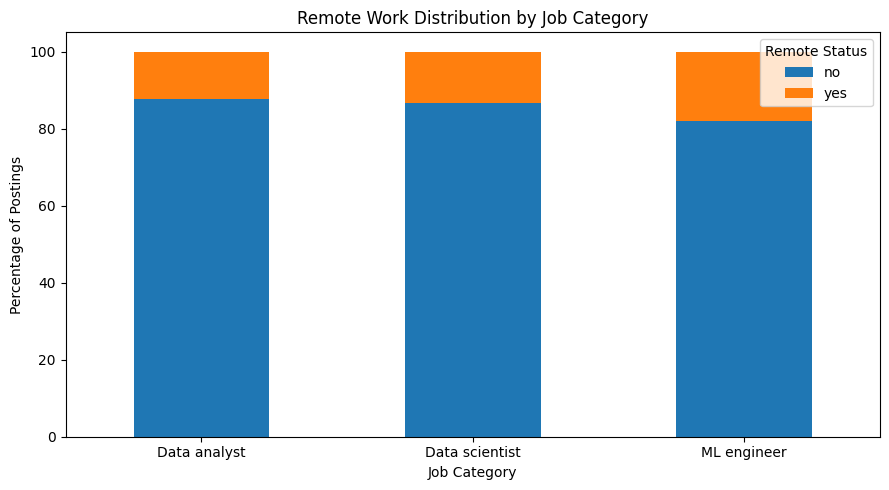

In [111]:
remote_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Remote Work Distribution by Job Category")
plt.xlabel("Job Category")
plt.ylabel("Percentage of Postings")
plt.legend(title="Remote Status")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretation:** *The chart shows that on-site or non-remote postings represent the majority of records across all three job categories. Data Analyst positions have a remote share of 12.31%, while Data Scientist positions have a slightly higher share of 13.23%. ML Engineer positions have the highest remote share, at 17.95%. This suggests that remote work is relatively more represented among ML Engineer postings in this dataset. However, the result describes the recorded postings only and should not be interpreted as proof that ML Engineer jobs generally offer more remote opportunities across the entire job market.*

**9-Analyze fresher opportunities by job category**

In [112]:
fresher_by_category = pd.crosstab(
    df_clean["job_category"],
    df_clean["is fresher?"]
)

fresher_by_category

is fresher?,no,unknown,yes
job_category,,,
Data analyst,153,432,0
Data scientist,222,395,3
ML engineer,56,100,0


In [113]:
#percentage
fresher_percentage = pd.crosstab(
    df_clean["job_category"],
    df_clean["is fresher?"],
    normalize="index"
) * 100

fresher_percentage.round(2)

is fresher?,no,unknown,yes
job_category,,,
Data analyst,26.15,73.85,0.00
Data scientist,35.81,63.71,0.48
ML engineer,35.90,64.10,0.00


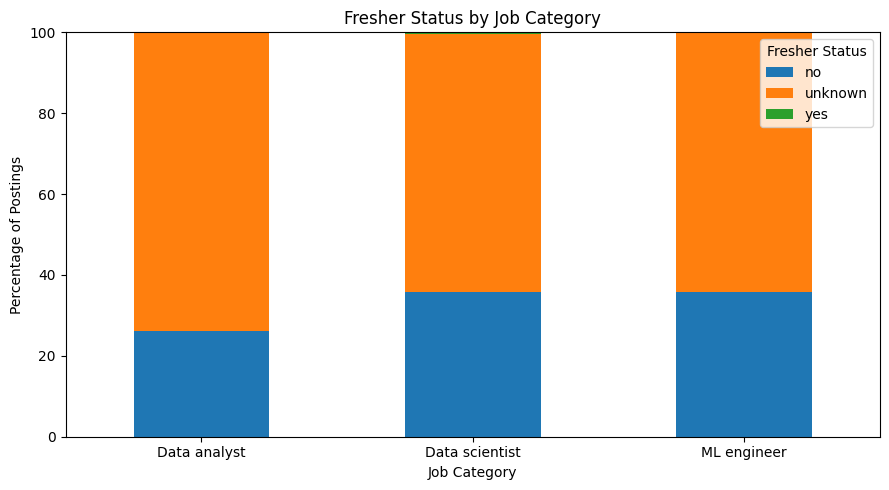

In [114]:
#Visualization
fresher_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Fresher Status by Job Category")
plt.xlabel("Job Category")
plt.ylabel("Percentage of Postings")
plt.legend(title="Fresher Status")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretation:** *Unknown fresher status is the largest group in every job category, representing 73.85% of Data Analyst postings, 63.71% of Data Scientist postings, and 64.10% of ML Engineer postings. Among postings with an explicitly recorded status, the dataset contains no confirmed fresher-friendly Data Analyst or ML Engineer postings, while only three Data Scientist postings are marked as suitable for freshers. These results should be interpreted cautiously because the high proportion of unknown values prevents a reliable assessment of the actual availability of entry-level opportunities. An unknown status does not necessarily mean that freshers are not eligible.*

**10-Explore the leading companies:**

In [115]:
top_companies = df_clean["company"].value_counts().head(10)

top_companies

company
Accenture                                          25
JPMorgan Chase & Co                                15
EY                                                 15
KPMG                                               10
Bosch Group                                         9
Deloitte                                            8
Mercedes-Benz Research and Development India...     8
Boston Consulting Group                             7
IBM                                                 7
Citi                                                7
Name: count, dtype: int64

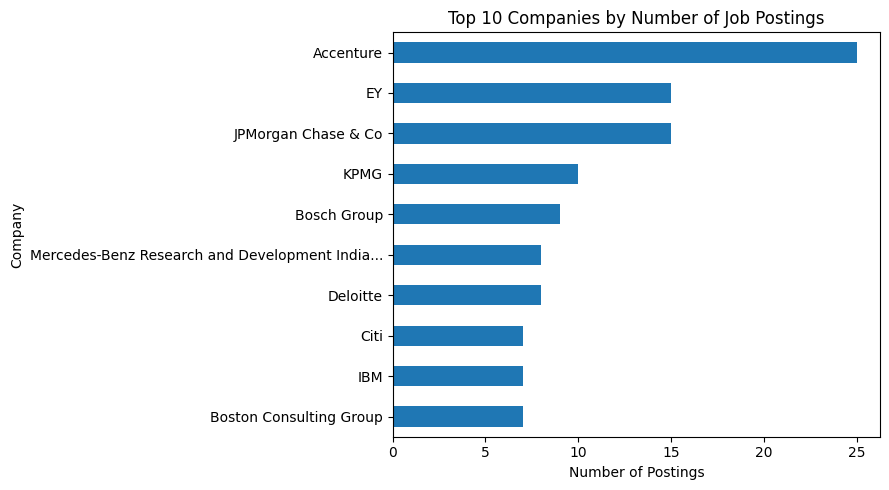

In [116]:
#Visualization
top_companies.sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Top 10 Companies by Number of Job Postings")
plt.xlabel("Number of Postings")
plt.ylabel("Company")
plt.tight_layout()
plt.show()

**Interpretation:** *Accenture has the highest number of recorded job postings, with 25, followed by JPMorgan Chase & Co and EY, with 15 postings each. KPMG appears next with 10 postings, while Bosch Group has nine. Other companies, including Deloitte, IBM, Boston Consulting Group, and Citi, also appear among the top 10. This distribution shows that Accenture is the most represented company in the dataset. However, these figures indicate the number of records collected for each company, not necessarily the total number of vacancies currently available at these organizations.*

*-Let's explore the job categories offered by these companies:*

In [117]:
top_company_names = top_companies.index

company_category = pd.crosstab(
    df_clean[df_clean["company"].isin(top_company_names)]["company"],
    df_clean[df_clean["company"].isin(top_company_names)]["job_category"]
)

company_category

job_category,Data analyst,Data scientist,ML engineer
company,,,
Accenture,12,12,1
Bosch Group,2,6,1
Boston Consulting Group,4,3,0
Citi,4,3,0
Deloitte,3,5,0
EY,9,4,2
IBM,3,3,1
JPMorgan Chase & Co,11,4,0
KPMG,6,4,0


**11-Comparing job categories across regions:**

In [118]:
region_by_category = pd.crosstab(
    df_clean["region"],
    df_clean["job_category"]
)

region_by_category

job_category,Data analyst,Data scientist,ML engineer
region,,,
+2 locations\nRemote,1,0,0
Agra,0,2,1
Ahmedabad,10,5,2
Amritsar,0,1,0
Anand Vihar,0,1,0
...,...,...,...
Vellore,1,0,0
Vijayawada,1,0,0
Vile Parle,0,0,1


In [119]:
#10 regions with the most postings
top_regions = df_clean["region"].value_counts().head(10).index

region_category_top10 = pd.crosstab(
    df_clean[df_clean["region"].isin(top_regions)]["region"],
    df_clean[df_clean["region"].isin(top_regions)]["job_category"]
)

region_category_top10

job_category,Data analyst,Data scientist,ML engineer
region,,,
Bengaluru,153,175,47
Chennai,17,32,6
Gurgaon,41,38,6
Hyderabad,42,55,17
India,30,27,7
Kolkata,10,16,2
Mumbai,52,40,7
Noida,20,16,3
Pune,34,46,11


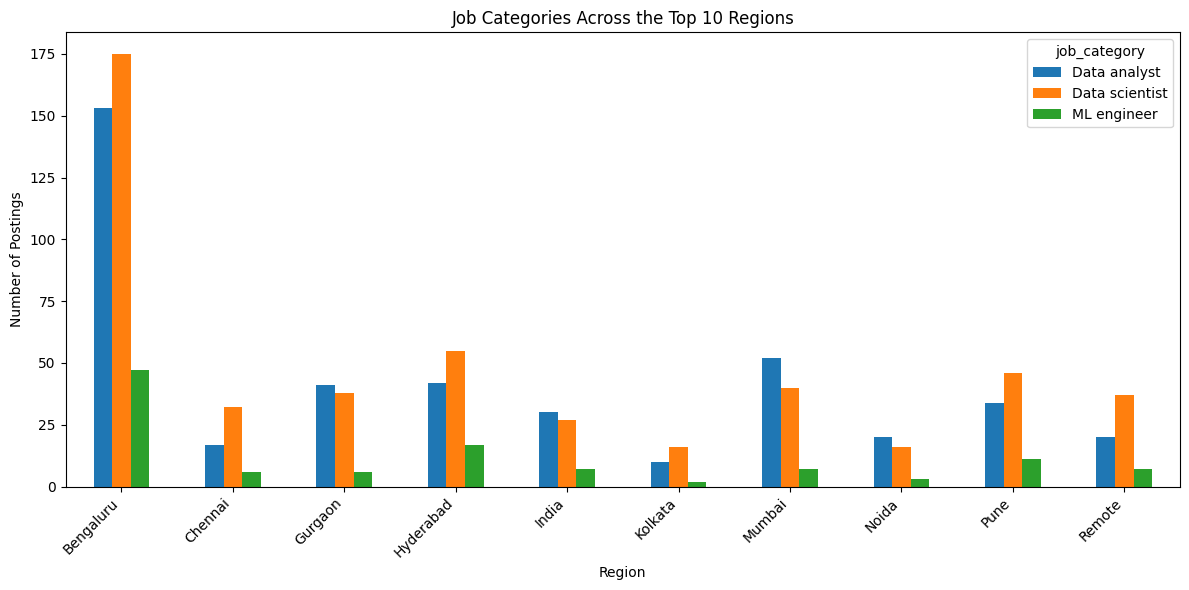

In [85]:
#Visualization 
region_category_top10.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Job Categories Across the Top 10 Regions")
plt.xlabel("Region")
plt.ylabel("Number of Postings")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Interpretation:** *Bengaluru has the highest number of postings across all three job categories, with 153 Data Analyst, 175 Data Scientist, and 47 ML Engineer postings. Hyderabad and Pune also show substantial representation across the categories. Data Scientist postings are particularly prominent in Bengaluru, Chennai, Hyderabad, Pune, Kolkata, and the region labeled Remote. In contrast, Data Analyst postings are more numerous than Data Scientist postings in Mumbai, Gurgaon, and Noida. These differences suggest that the distribution of recorded job categories varies by region. However, the category counts should be considered alongside differences in the overall number of postings collected for each location.*

**12-investigate combinations of skills:**

In [120]:
skills_text = (
    df_clean["skills required"]
    .fillna("Unknown")
    .astype(str)
    .str.casefold()
)

python_sql_count = (
    skills_text.str.contains(r"\bpython\b", regex=True)
    & skills_text.str.contains(r"\bsql\b", regex=True)
).sum()

print("Postings mentioning both Python and SQL:", python_sql_count)

Postings mentioning both Python and SQL: 4


**Interpretation:** *The analysis identifies four postings that explicitly mention both Python and SQL in their recorded skill information. This demonstrates how individual skills can be examined in combination to investigate recurring skill requirements. However, because 60.35% of postings have unknown skill information, this result should not be interpreted as the actual prevalence of Python and SQL requirements across the entire dataset. It represents only the postings in which both skills are explicitly recorded.*


## Dataset Limitations

- **Geographical Coverage:** The dataset contains job postings from India. Therefore, the findings cannot automatically be generalized to other countries.

- **Missing Information:** Many job postings contain `"Unknown"` values for required skills or fresher status, limiting the conclusions that can be drawn from these variables.

- **Duplicate Records:** The dataset contains exact duplicate rows that require inspection and appropriate treatment to avoid potentially misleading results.

- **Skill Representation:** Required skills are stored as text, with multiple skills sometimes appearing in a single cell. The analysis depends on the consistency and completeness of these entries.

- **Dataset Representativeness:** The dataset contains 1,503 job postings and may not fully represent the Indian AI and data job market.

- **Job Posting Counts:** The number of postings associated with a company or region does not necessarily reflect the total number of vacancies available in the market.

- **Data Freshness:** If the dates of data collection are unavailable, it is difficult to determine whether the postings reflect current hiring trends.


In [121]:
df_clean.to_csv(
    "../data/processed/ai_jobs_clean.csv",
    index=False
)